# SAT3 database: nonlinear exploration

This notebook contains the expansive search for nonlinear relationships across
the 43 supplied simulations. Run it from top to bottom using the course `.venv`
environment. It loads the original data itself; you do not need to run
[01_load_cases.ipynb](01_load_cases.ipynb) first.

The first notebook contains assignment Steps 1–3 and explains the data-loading
code. Here, `sat3_loader.py` provides those same readers, and
`nonlinear_tools.py` provides the analysis functions. Keep both files in this
notebook's folder.

Plots appear inline and are saved in `figures/nonlinear/`. The final cell saves
the result tables to `nonlinear_results.json`. The source data are read only.

## Load the cases and prepare labels


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Locate the same source files from analysis/, A1/, or the course folder.
data_locations = (
    Path("datasets/SAT3_dataset_v1/SAT3_dataset/data"),
    Path("assignments/A1/datasets/SAT3_dataset_v1/SAT3_dataset/data"),
)
DATA_DIR = next(
    (parent / relative
     for parent in (Path.cwd(), *Path.cwd().parents)
     for relative in data_locations
     if (parent / relative).is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Open this notebook from inside the DSC180A folder.")

analysis_dir = DATA_DIR.parents[3] / "analysis"
if str(analysis_dir) not in sys.path:
    sys.path.insert(0, str(analysis_dir))
from sat3_loader import load_cases, SCALAR_PARAMETERS, SPECIES_PARAMETERS

records, errors = load_cases(DATA_DIR)
if errors:
    raise ValueError(f"Some cases failed to load: {errors}")
if len(records) != 43:
    raise ValueError(f"Expected 43 supplied cases, found {len(records)}")
df = pd.DataFrame(records).set_index("case")
if not df.index.is_unique:
    raise ValueError("Case names must be unique")
if not (
    df["NS"].eq(2).all()
    and df["species_type_1"].eq("electron").all()
    and df["species_type_2"].isin(["H", "D", "T"]).all()
):
    raise ValueError("Check species ordering before assigning electron/ion labels")

plot_df = df.copy()
plot_df["letter"] = df.index.to_series().str.rsplit("_", n=1).str[0]
plot_df["ion"] = df["species_type_2"]
flux_aliases = {
    "Gamma_e": "Gamma_1", "Gamma_i": "Gamma_2",
    "Q_e": "Q_1", "Q_i": "Q_2",
    "Pi_e": "Pi_1", "Pi_i": "Pi_2",
}
for alias, source in flux_aliases.items():
    plot_df[alias] = df[source]
if plot_df[["Q_i", "Q_e"]].le(0).any().any():
    raise ValueError("Inspect nonpositive heat fluxes before log/ratio plots")

complete_letters = [
    letter for letter, group in plot_df.groupby("letter")
    if len(group) == 3 and set(group["ion"]) == {"H", "D", "T"}
]
input_columns = list(SCALAR_PARAMETERS) + [
    f"{name}_{s}" for name in SPECIES_PARAMETERS for s in (1, 2)
]
non_mass_inputs = [name for name in input_columns if name != "MASS_2"]
for letter in complete_letters:
    group = plot_df.loc[plot_df["letter"].eq(letter)]
    if group[non_mass_inputs].nunique().gt(1).any():
        raise ValueError(f"Letter {letter} changes inputs other than ion mass")

print(f"Loaded {len(df)} cases across {plot_df['letter'].nunique()} letter groups.")
print(f"Complete H/D/T triplets: {len(complete_letters)}")


Loaded 43 cases across 26 letter groups.
Complete H/D/T triplets: 8


In [2]:
input_titles = {
    "XNUE": "Electron collision frequency",
    "RMIN_LOC": "Normalized minor radius",
    "KAPPA_LOC": "Elongation",
    "Q_LOC": "Safety factor",
    "Q_PRIME_LOC": "Magnetic-shear input",
    "DRMAJDX_LOC": "Major-radius gradient",
    "MASS_2": "Ion mass relative to deuterium",
    "TAUS_2": "Normalized ion temperature",
    "RLTS_1": "Electron temperature gradient",
    "RLTS_2": "Ion temperature gradient",
    "RLNS_1": "Electron density gradient",
    "RLNS_2": "Ion density gradient",
}

FIGURE_DIR = analysis_dir / "figures"
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ion_colors = {"H": "#0072B2", "D": "#D55E00", "T": "#009E73"}
ion_markers = {"H": "o", "D": "s", "T": "^"}


## Extended exploration: nonlinear relationships

A straight-line correlation can miss a curved trend, a reversal, or an effect
that changes with another input. We will examine those possibilities using:

1. All **120 unique pairs** among 16 nonduplicate variables, including inputs,
   heat/particle fluxes, momentum fluxes, and a derived magnetic-shear input.
2. Scatter plots and controlled scans of all **10 distinct physical input
   coordinates**, focusing on `Q_i`, `Q_e`, and `Gamma_e`.
3. Every available matched four-case comparison for two-input interactions.
4. **144 one-input model configurations**, followed by **20 multivariate
   outcome/model comparisons** with entire letter groups held out.

This is exploratory work on 43 designed simulations, not a random sample of
plasmas. We report effect sizes, observed comparisons, and held-out prediction
errors rather than assigning significance to a large number of searched patterns.
Selecting a promising relationship on these same data does not independently
confirm it. The helper functions are in `nonlinear_tools.py`; the cells below
show the choices, results, plots, and interpretation.

In [3]:
import sys
import json

analysis_dir = FIGURE_DIR.parent
if str(analysis_dir) not in sys.path:
    sys.path.insert(0, str(analysis_dir))
from nonlinear_tools import (
    dependency_screen, univariate_sweep, nested_model_comparison,
    matched_rectangles, baseline_scans,
)

nl_df = plot_df.copy()
nl_df["magnetic_shear"] = nl_df["Q_PRIME_LOC"] * nl_df["RMIN_LOC"] ** 2 / nl_df["Q_LOC"] ** 2
nl_features = [
    "XNUE", "RLTS_2", "RLNS_2", "MASS_2", "TAUS_2",
    "magnetic_shear", "Q_LOC", "RMIN_LOC", "KAPPA_LOC", "DRMAJDX_LOC",
]
nl_targets = ["Q_i", "Q_e", "Gamma_e"]
nl_outputs = nl_targets + ["Pi_e", "Pi_i"]
nl_screen_inputs = nl_features + ["Q_PRIME_LOC"]
nl_groups = nl_df["letter"].to_numpy()
nl_labels = {**input_titles, "magnetic_shear": "Magnetic shear"}
nl_saved_figures = []
NL_FIGURE_DIR = FIGURE_DIR / "nonlinear"
NL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Do not count identical columns as additional independent discoveries.
nl_duplicates = {"RLTS_1": "RLTS_2", "RLNS_1": "RLNS_2", "Gamma_i": "Gamma_e"}
for duplicate, retained in nl_duplicates.items():
    if not nl_df[duplicate].equals(nl_df[retained]):
        raise ValueError(f"Revisit deduplication: {duplicate} differs from {retained}")
if not np.isfinite(nl_df[nl_screen_inputs + nl_outputs].to_numpy()).all():
    raise ValueError("Resolve non-finite values before nonlinear analysis")


def nl_save(fig, name):
    path = NL_FIGURE_DIR / f"{name}.png"
    fig.savefig(path, dpi=160, bbox_inches="tight", facecolor="white")
    if path not in nl_saved_figures:
        nl_saved_figures.append(path)
    plt.show()
    plt.close(fig)


print(f"{len(nl_df)} cases, {len(set(nl_groups))} letter groups, {len(nl_features)} physical input coordinates")
print("Duplicate columns excluded from the search:", nl_duplicates)

43 cases, 26 letter groups, 10 physical input coordinates
Duplicate columns excluded from the search: {'RLTS_1': 'RLTS_2', 'RLNS_1': 'RLNS_2', 'Gamma_i': 'Gamma_e'}


### Check what the input coordinates mean

`Q_PRIME_LOC` already encodes a nonlinear relationship between inputs.
[GACODE defines it](https://gafusion.github.io/doc/tglf/tglf_list.html#q-prime-loc)
as (q^2 s/(r/a)^2), so we recover magnetic shear as

[
s = mathrm{Q_PRIME_LOC},rac{mathrm{RMIN_LOC}^2}{mathrm{Q_LOC}^2}.
]

We retain the encoded input in the dependency screen, but use `magnetic_shear`
in its place for models and matched comparisons. This makes it possible to
recognize the radius and safety-factor scans as changes at fixed shear. A
relationship caused by this definition is not a newly discovered transport law.
The two temperature gradients are tied, as are the two density gradients.
`RLTS_2` and `RLNS_2` below therefore represent **joint species-gradient changes**.

The coverage table counts the observed settings. Three or four settings can
suggest curvature, but cannot establish a detailed response curve or a critical
threshold between them.

In [4]:
nl_coverage = pd.DataFrame(index=nl_features)
nl_coverage["distinct_settings"] = nl_df[nl_features].round(12).nunique()
nl_coverage["nonbaseline_cases"] = [
    int((~np.isclose(nl_df[name], nl_df.at["a_D", name], rtol=1e-10, atol=1e-12)).sum())
    for name in nl_features
]
nl_coverage["observed_settings"] = [
    ", ".join(f"{value:g}" for value in sorted(nl_df[name].round(12).unique()))
    for name in nl_features
]
display(nl_coverage)
print("Examples where the encoded input changes but magnetic shear stays at 1:")
display(nl_df.loc[["a_D", "n_D", "o_D", "v_D", "w_D"],
                  ["Q_LOC", "RMIN_LOC", "Q_PRIME_LOC", "magnetic_shear"]])

,distinct_settings,nonbaseline_cases,observed_settings
XNUE,4,10,"0.01, 0.05, 0.1, 1"
RLTS_2,4,9,"1.5, 2.25, 3, 3.5"
RLNS_2,3,12,"1, 2, 3"
MASS_2,3,18,"0.5, 1, 1.5"
TAUS_2,3,2,"0.5, 1, 1.5"
magnetic_shear,4,3,"0.25, 0.5, 1, 1.5"
Q_LOC,3,2,"1.5, 2, 2.5"
RMIN_LOC,3,2,"0.25, 0.5, 0.75"
KAPPA_LOC,4,3,"1, 1.25, 1.5, 2"
DRMAJDX_LOC,4,3,"-0.5, -0.25, -0.125, 0"


Examples where the encoded input changes but magnetic shear stays at 1:


,Q_LOC,RMIN_LOC,Q_PRIME_LOC,magnetic_shear
case,,,,
a_D,2.0,0.50,16.000000,1.0
n_D,1.5,0.50,9.000000,1.0
o_D,2.5,0.50,25.000000,1.0
v_D,2.0,0.75,7.111111,1.0
w_D,2.0,0.25,64.000000,1.0


### Screen linear, monotonic, and more general dependence

**Pearson** describes linear association. **Spearman** uses ranks and can reveal
monotonic curved trends. **Distance correlation** can also respond to
nonmonotonic relationships; it has no direction. Its sample value is biased
upward, so a nonzero value by itself is not evidence of a relationship. The
[original distance-correlation paper](https://arxiv.org/abs/0803.4101) describes
the measure; our helper implements the usual centered-distance sample statistic.

The metrics have different meanings. Subtracting one from another is not a
formal test for nonlinearity. We use a larger absolute Spearman than Pearson
value only to select relationships worth inspecting visually. No asymptotic
Spearman p-values are used; [SciPy's documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)
notes the small-sample limitation, and the grouped scan design also needs care.

For each pair, we recompute all three metrics after deleting each letter in
turn. The min/max columns measure sensitivity to those deletions; they are
**not confidence intervals**. `nl_dependencies` retains all 120 pairs, including
input-input and output-output comparisons. The heat maps show all 55
input-output pairs.

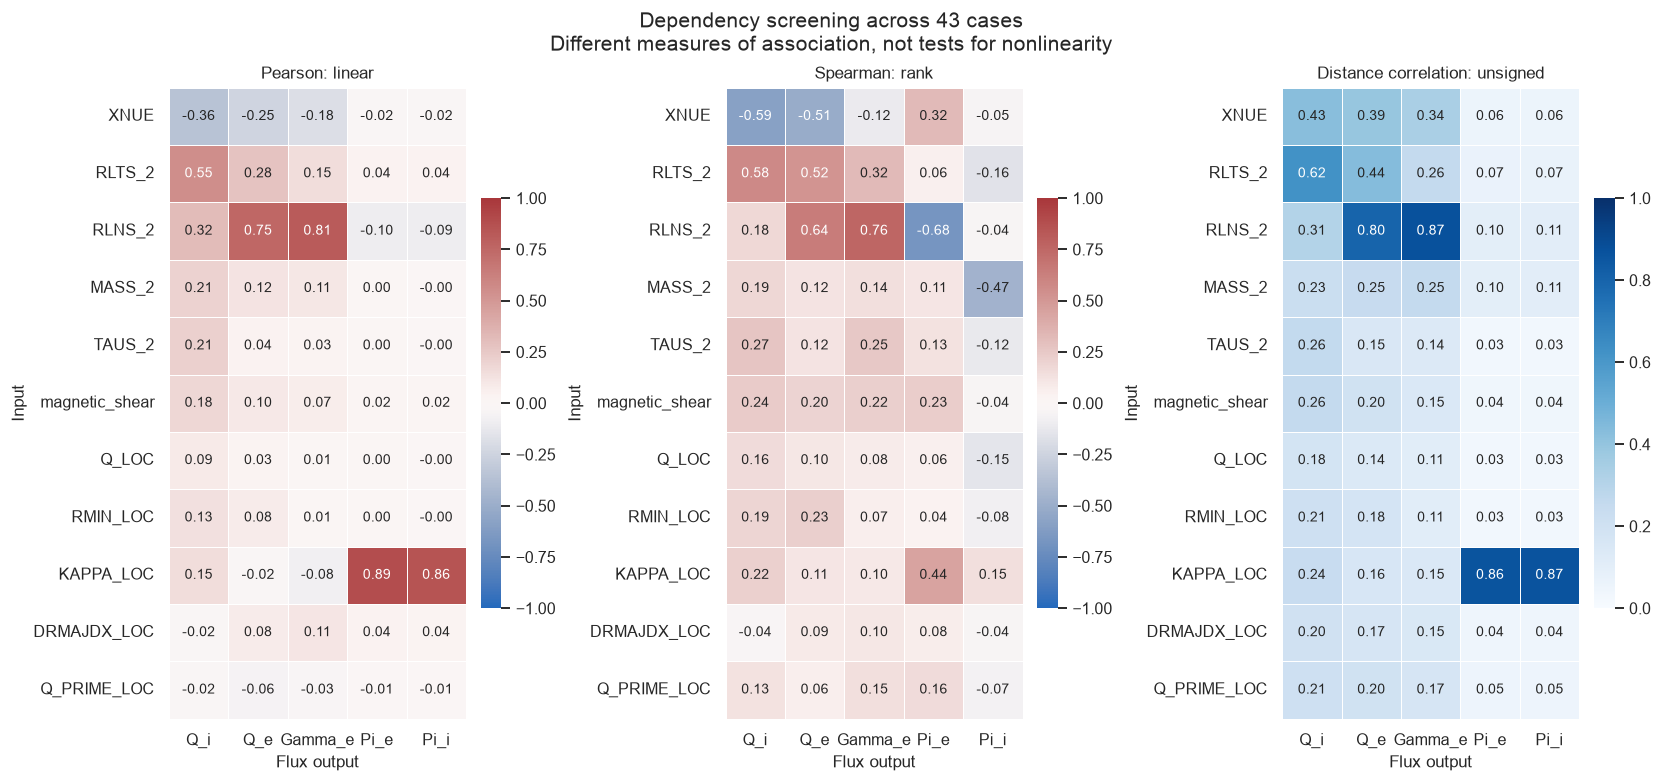

,variable_1,variable_2,pearson,spearman,distance_correlation,spearman_delete_min,spearman_delete_max
11,XNUE,Q_e,-0.248,-0.513,0.392,-0.587,-0.368
25,RLTS_2,Q_e,0.278,0.518,0.436,0.347,0.604
10,XNUE,Q_i,-0.355,-0.591,0.429,-0.625,-0.465
62,TAUS_2,Gamma_e,0.034,0.252,0.139,0.122,0.281
26,RLTS_2,Gamma_e,0.151,0.322,0.256,0.145,0.442
72,magnetic_shear,Gamma_e,0.070,0.222,0.146,0.153,0.260
88,RMIN_LOC,Q_e,0.078,0.226,0.176,0.161,0.252
107,Q_PRIME_LOC,Gamma_e,-0.034,0.148,0.168,0.088,0.195
105,Q_PRIME_LOC,Q_i,-0.017,0.130,0.207,0.068,0.210
71,magnetic_shear,Q_e,0.097,0.202,0.197,0.099,0.241


In [5]:
nl_dependencies = dependency_screen(
    nl_df, nl_screen_inputs + nl_outputs, nl_groups, nl_screen_inputs
)
nl_input_output = nl_dependencies.loc[nl_dependencies["kind"].eq("input-output")]
fig, axes = plt.subplots(1, 3, figsize=(15, 7), layout="constrained")
for ax, metric, title in zip(
    axes, ["pearson", "spearman", "distance_correlation"],
    ["Pearson: linear", "Spearman: rank", "Distance correlation: unsigned"],
):
    matrix = nl_input_output.pivot(index="variable_1", columns="variable_2", values=metric)
    matrix = matrix.reindex(index=nl_screen_inputs, columns=nl_outputs)
    is_distance = metric == "distance_correlation"
    sns.heatmap(
        matrix, annot=True, fmt=".2f", ax=ax,
        vmin=0 if is_distance else -1, vmax=1,
        cmap="Blues" if is_distance else "vlag", linewidths=0.4,
        cbar_kws={"shrink": 0.65}, annot_kws={"size": 9},
    )
    ax.set(title=title, xlabel="Flux output", ylabel="Input")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
    ax.grid(False)
fig.suptitle("Dependency screening across 43 cases\nDifferent measures of association, not tests for nonlinearity", fontsize=14)
nl_save(fig, "01_dependency_screen")

nl_primary_screen = nl_input_output.loc[nl_input_output["variable_2"].isin(nl_targets)]
display(nl_primary_screen.sort_values("rank_minus_abs_linear", ascending=False).head(12)[[
    "variable_1", "variable_2", "pearson", "spearman", "distance_correlation",
    "spearman_delete_min", "spearman_delete_max",
]].round(3))

Collision frequency is worth examining: for `Q_i`, Pearson is **−0.355** while
Spearman is **−0.591**. For `Q_e`, they are **−0.248** and **−0.513**. The
collision-frequency/`Q_i` Spearman value remains between approximately **−0.625
and −0.465** when deleting one letter. That suggests an association beyond a
single letter, but does not isolate it from the other varied inputs.

Some of the largest rank/Pearson disagreements involve momentum flux. Those
rankings include values near zero and much smaller than the few largest
momentum values. They do not establish a physically meaningful momentum effect;
we retain them in the complete screen but focus the modeling on heat and
particle flux. Output-output associations likewise do not establish that one
flux causes another.

To inspect any pair, filter `nl_dependencies`, for example with
`nl_dependencies.query("variable_1 == 'XNUE' and variable_2 == 'Q_i'")`.

### View every physical input against the primary fluxes

Each panel includes all 43 cases, colored by ion isotope. Collision frequency
uses a log horizontal axis. No line joins the pooled cases because their other
inputs differ. These plots show where a proposed smooth curve would rest on
only one or two nonbaseline cases.

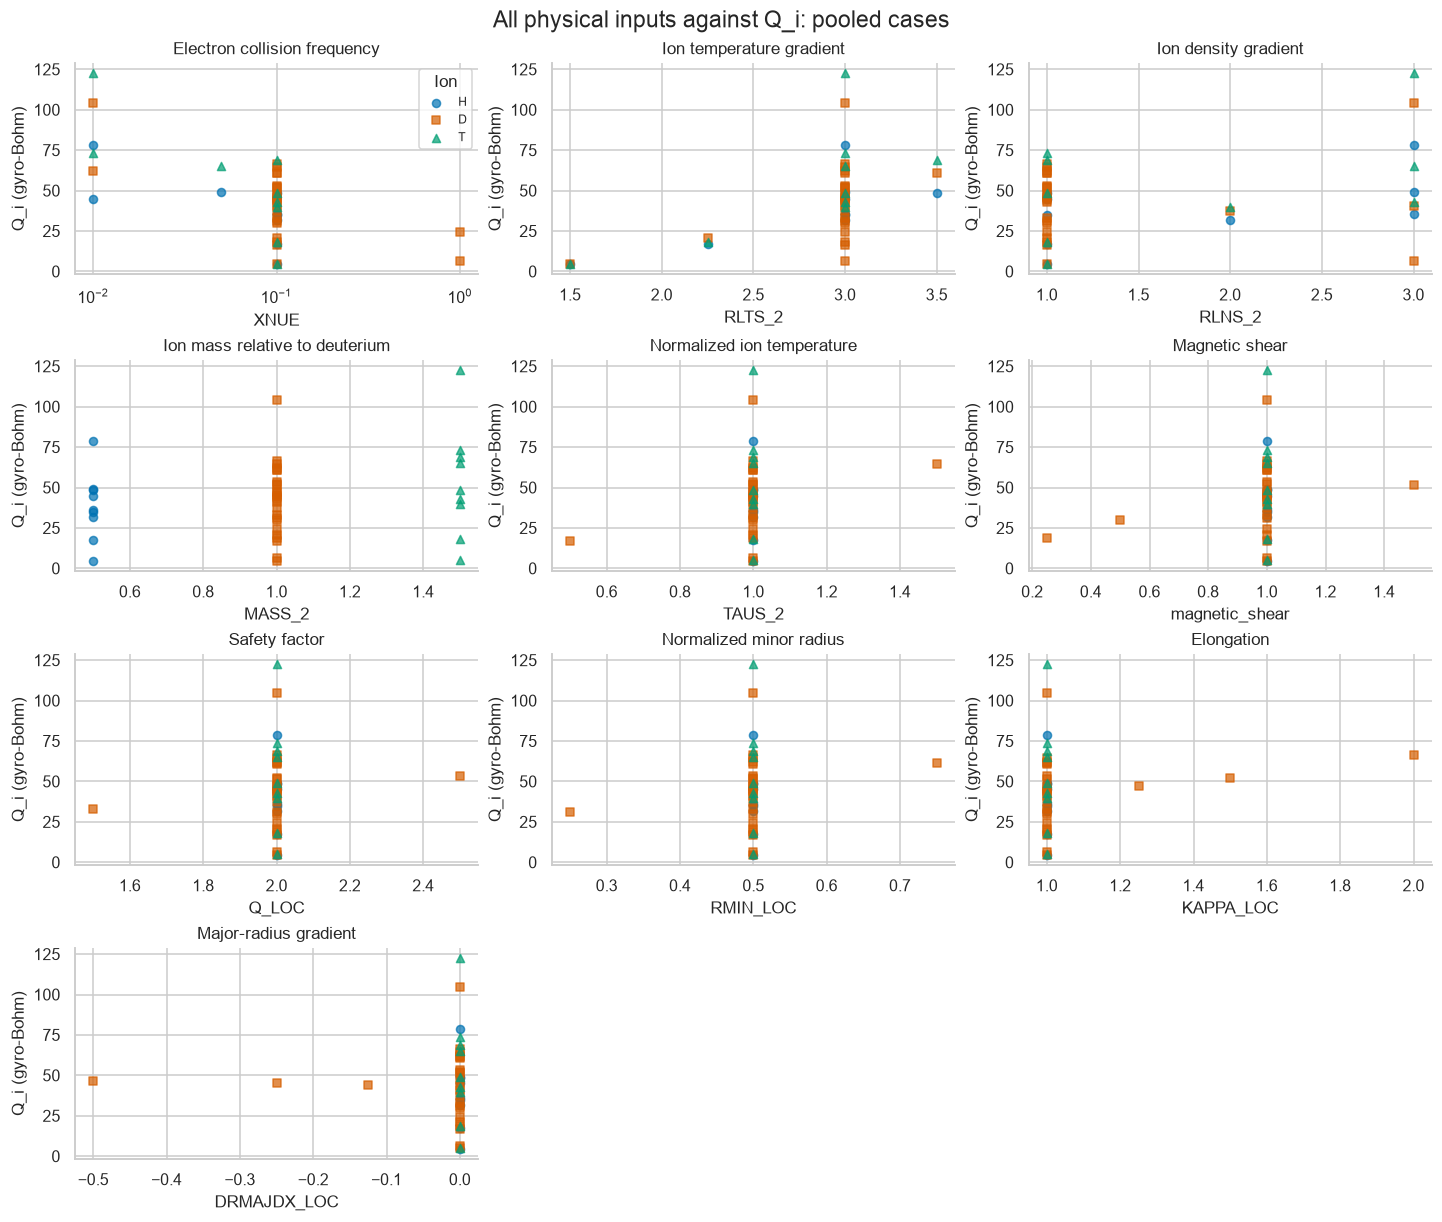

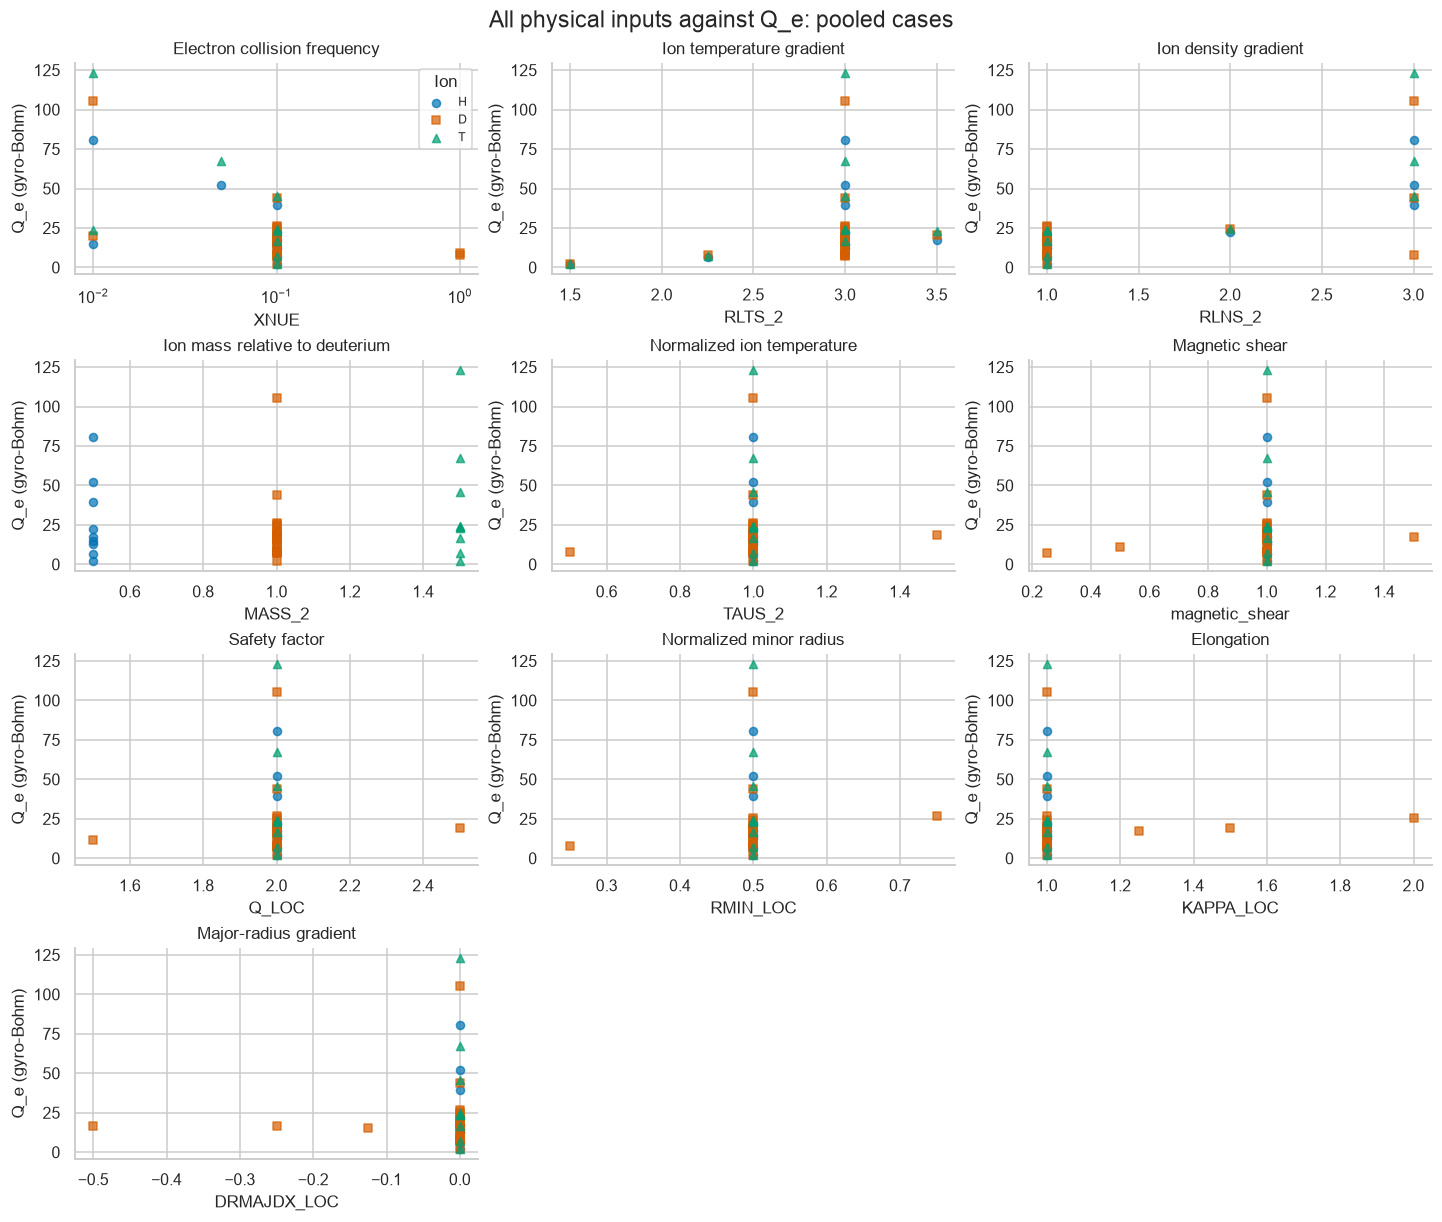

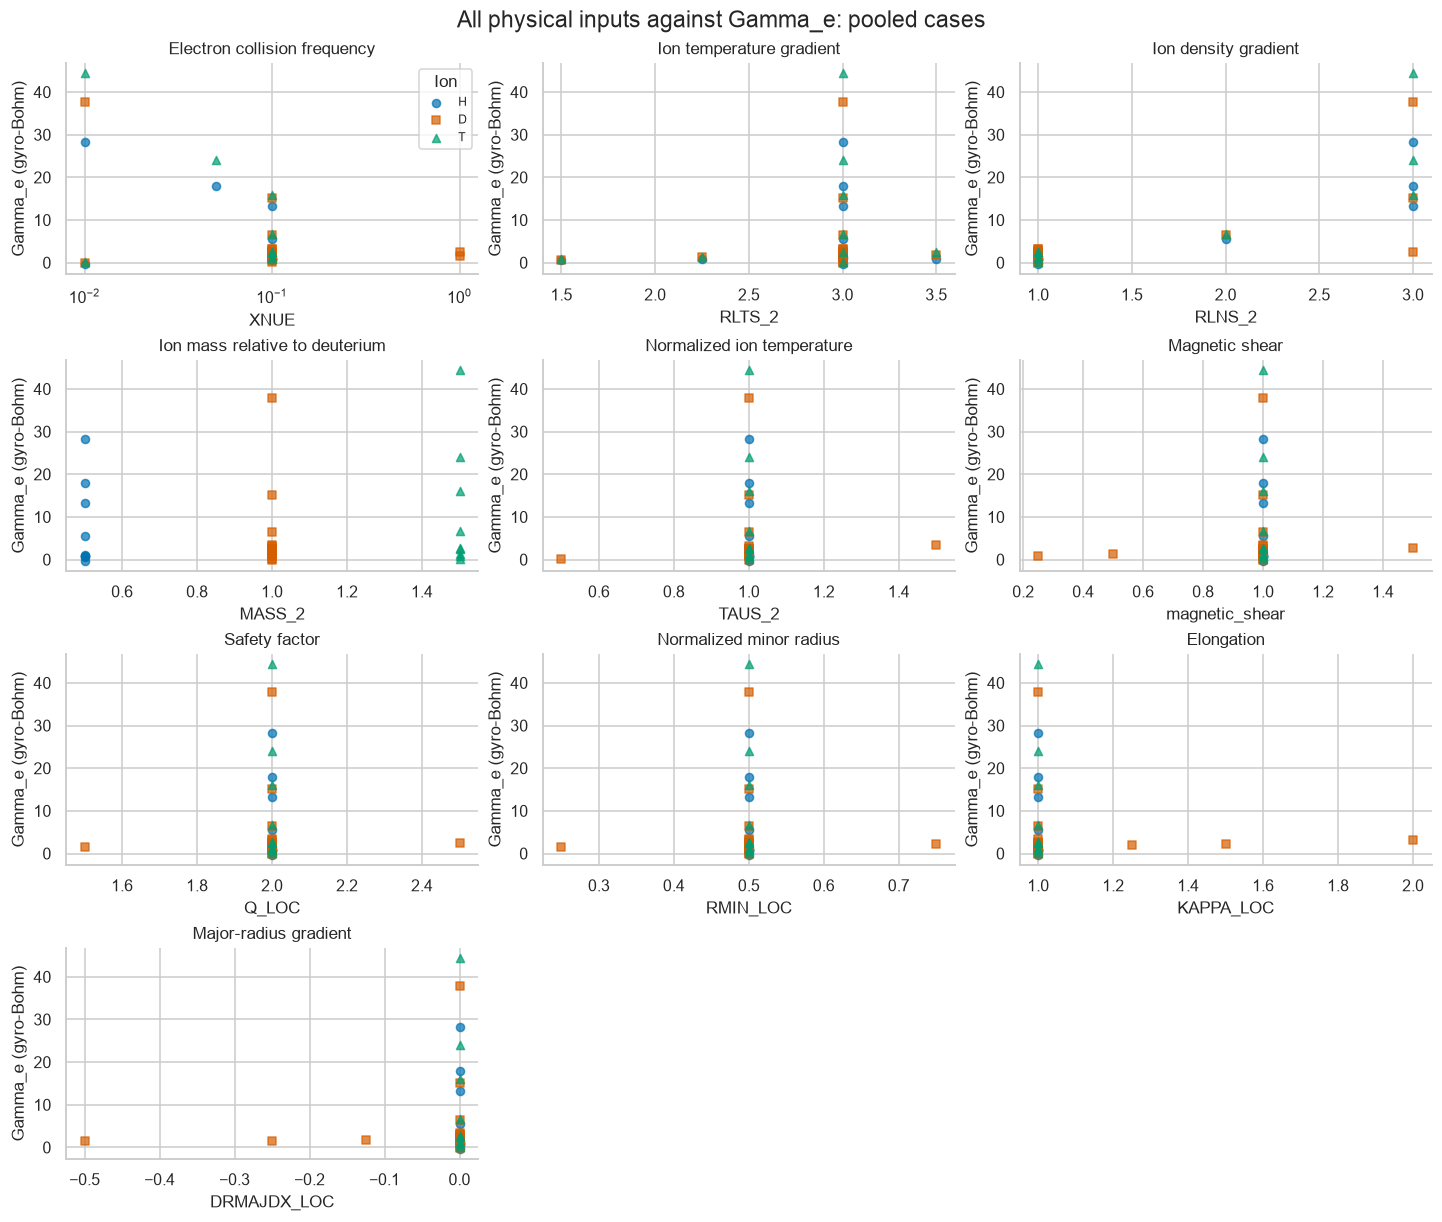

In [6]:
for target in nl_targets:
    fig, axes = plt.subplots(4, 3, figsize=(13, 11), layout="constrained")
    for ax, feature in zip(axes.flat, nl_features):
        for ion in ("H", "D", "T"):
            group = nl_df.loc[nl_df["ion"].eq(ion)]
            ax.scatter(group[feature], group[target], color=ion_colors[ion],
                       marker=ion_markers[ion], s=28, alpha=0.7, label=ion)
        if feature == "XNUE":
            ax.set_xscale("log")
        ax.set(title=nl_labels[feature], xlabel=feature, ylabel=f"{target} (gyro-Bohm)")
    for ax in list(axes.flat)[len(nl_features):]:
        ax.set_visible(False)
    axes.flat[0].legend(title="Ion", fontsize=8)
    fig.suptitle(f"All physical inputs against {target}: pooled cases", fontsize=15)
    nl_save(fig, f"02_scatter_atlas_{target}")

### Hold the other inputs fixed: baseline scans

For each input, select cases whose other physical input coordinates match
`a_D`. Most panels therefore show only deuterium; the mass panel uses `a_H`,
`a_D`, and `a_T`. The checks use the recovered shear coordinate, so changes to
encoded `Q_PRIME_LOC` required by radius or safety factor do not masquerade as
extra independent changes.

Lines connect measured simulation outputs, not fitted response curves. For
collision frequency, horizontal spacing is logarithmic. For each scan, the
slope table records changes between adjacent settings. A reversal in slope is
an observed turn; unequal slopes suggest curvature at the sampled settings.

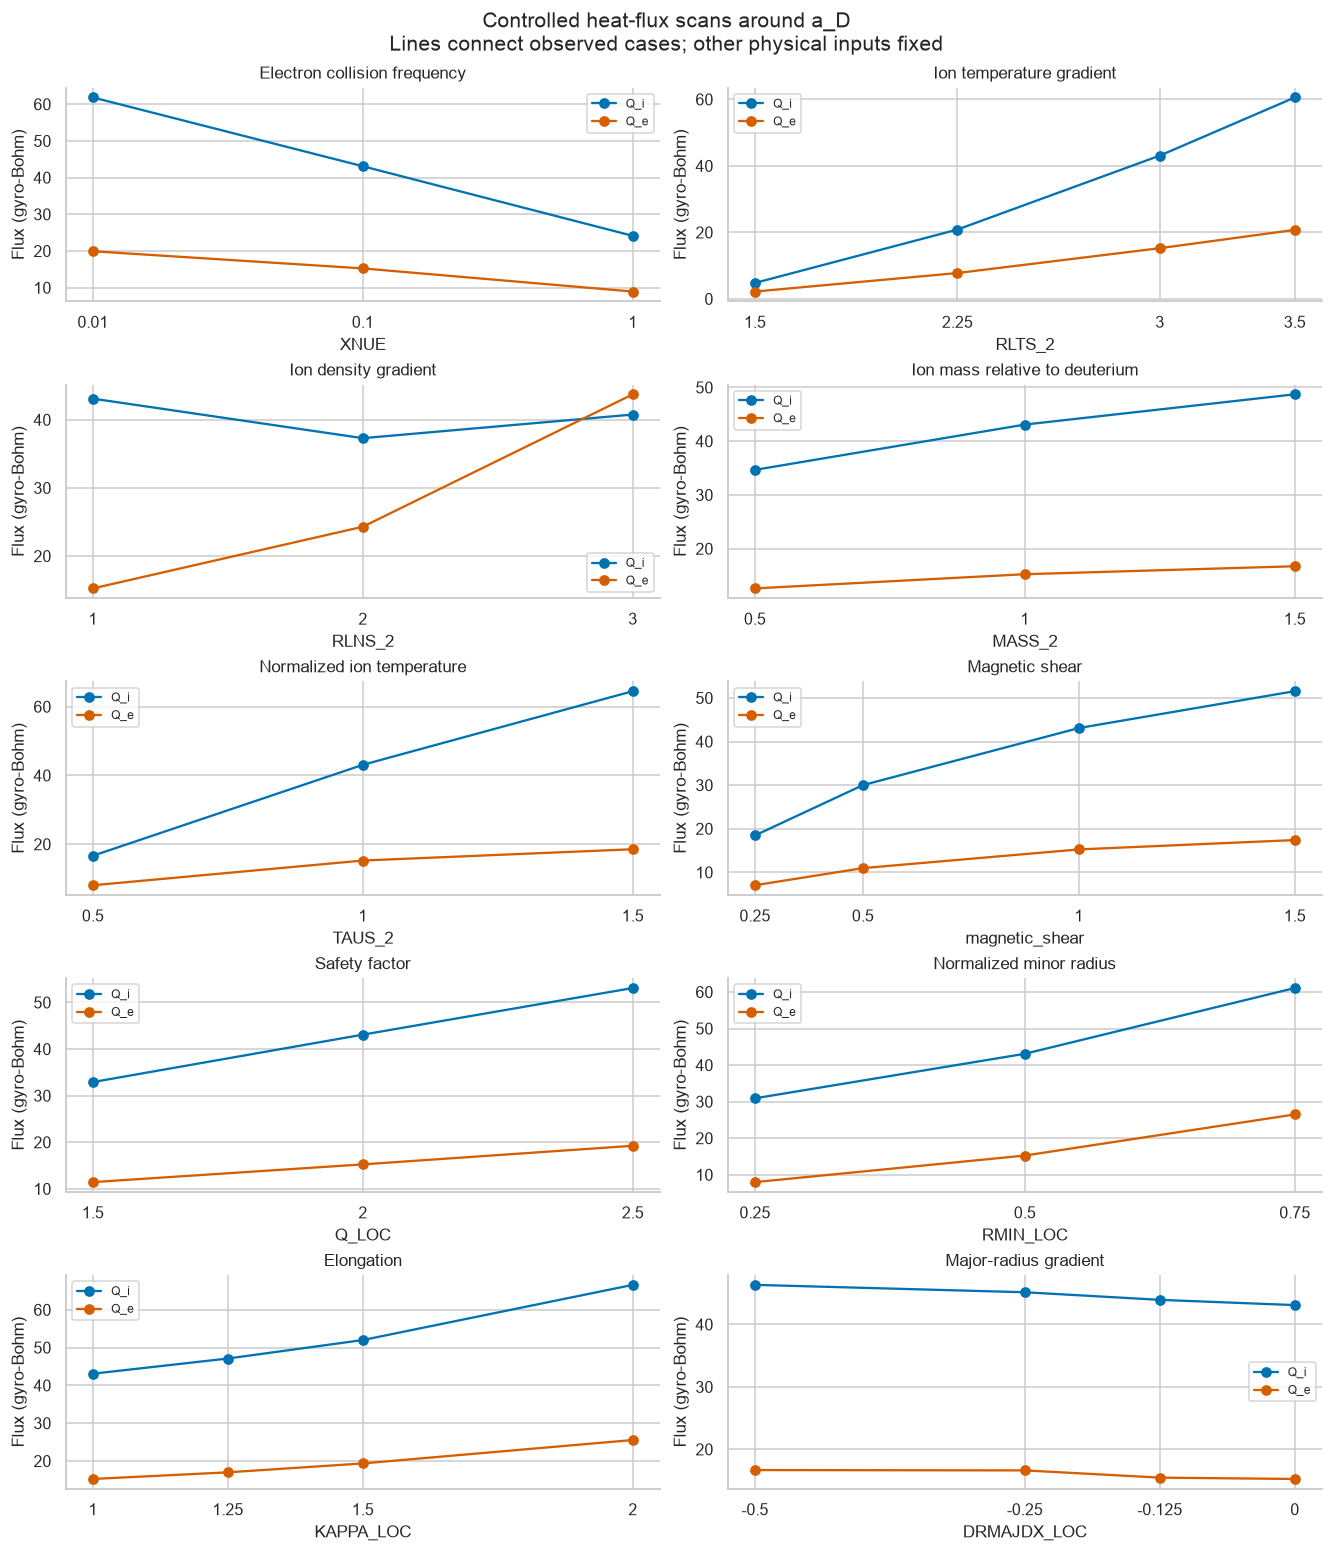

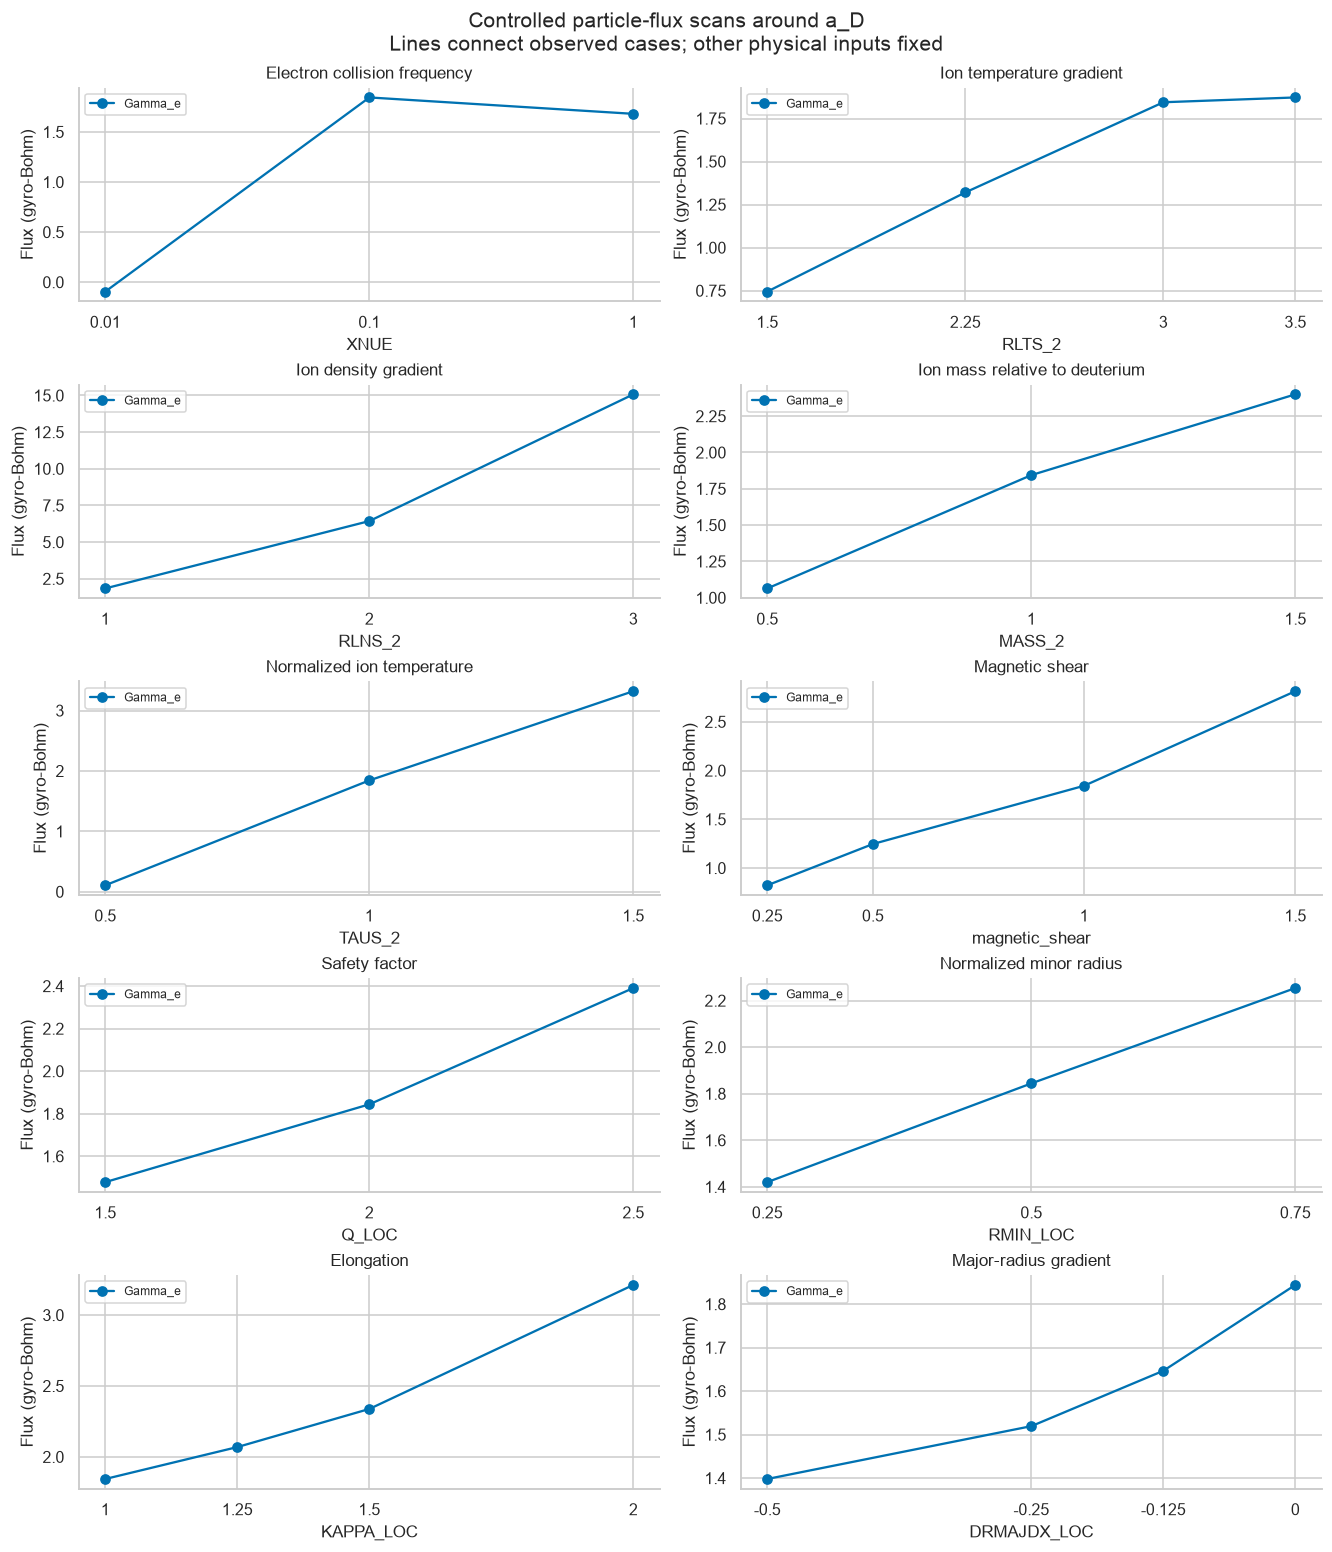

,input,target,settings,cases,slope_coordinate,first_slope,last_slope,turn_in_observed_values
0,XNUE,Q_i,3,"j_D, a_D, k_D",log10(XNUE),-18.758,-18.963,False
3,RLTS_2,Q_i,4,"b_D, c_D, a_D, d_D",RLTS_2,21.417,34.970,False
6,RLNS_2,Q_i,3,"a_D, e_D, f_D",RLNS_2,-5.800,3.467,True
9,MASS_2,Q_i,3,"a_H, a_D, a_T",MASS_2,16.856,11.264,False
12,TAUS_2,Q_i,3,"l_D, a_D, m_D",TAUS_2,52.892,42.842,False
15,magnetic_shear,Q_i,4,"g_D, h_D, a_D, i_D",magnetic_shear,46.176,16.922,False
18,Q_LOC,Q_i,3,"n_D, a_D, o_D",Q_LOC,20.356,20.014,False
21,RMIN_LOC,Q_i,3,"w_D, a_D, v_D",RMIN_LOC,48.752,71.968,False
24,KAPPA_LOC,Q_i,4,"a_D, p_D, q_D, r_D",KAPPA_LOC,16.056,29.186,False
27,DRMAJDX_LOC,Q_i,4,"u_D, t_D, s_D, a_D",DRMAJDX_LOC,-4.732,-6.728,False


In [7]:
nl_scans = baseline_scans(nl_df, nl_features)
nl_slope_rows = []
for feature, scan in nl_scans.items():
    x = scan[feature].to_numpy()
    coordinate = np.log10(x) if feature == "XNUE" else x
    for target in nl_targets:
        slopes = np.diff(scan[target]) / np.diff(coordinate)
        nl_slope_rows.append({
            "input": feature, "target": target, "settings": len(scan),
            "cases": ", ".join(scan.index),
            "slope_coordinate": "log10(XNUE)" if feature == "XNUE" else feature,
            "first_slope": slopes[0], "last_slope": slopes[-1],
            "turn_in_observed_values": bool((slopes > 0).any() and (slopes < 0).any()),
        })
nl_scan_slopes = pd.DataFrame(nl_slope_rows)

for panel_name, quantities in [("heat", ["Q_i", "Q_e"]), ("particle", ["Gamma_e"])]:
    fig, axes = plt.subplots(5, 2, figsize=(12, 14), layout="constrained")
    for ax, feature in zip(axes.flat, nl_features):
        scan = nl_scans[feature]
        for quantity, color in zip(quantities, ["#0072B2", "#D55E00"]):
            ax.plot(scan[feature], scan[quantity], "o-", color=color, label=quantity)
        if feature == "XNUE":
            ax.set_xscale("log")
        ax.set_xticks(scan[feature], [f"{value:g}" for value in scan[feature]])
        ax.set(title=nl_labels[feature], xlabel=feature, ylabel="Flux (gyro-Bohm)")
        ax.legend(fontsize=8)
    fig.suptitle(f"Controlled {panel_name}-flux scans around a_D\nLines connect observed cases; other physical inputs fixed", fontsize=14)
    nl_save(fig, f"03_controlled_{panel_name}_scans")
display(nl_scan_slopes.loc[nl_scan_slopes["target"].eq("Q_i")].round(3))

Three examples stand out in these controlled scans:

- Raising the shared density gradient **1 → 2 → 3** gives deuterium ion heat
  flux **43.101 → 37.301 → 40.768**. The three observed points form a dip.
- At baseline density gradient, increasing collisions **0.01 → 0.1 → 1** gives
  `Q_i` **61.859 → 43.101 → 24.138**. The decreases per tenfold collision increase
  are **18.758** and **18.963**: nearly a straight line in log collision frequency.
- Along the shared temperature-gradient scan, the adjacent `Q_i` slopes rise
  from about **21.4** to **29.7** to **35.0** per unit gradient. The sampled
  response steepens; these four settings do not determine a critical gradient.

A fitted quadratic through three points would reproduce them exactly without
providing an independent check. The point-to-point comparisons above make the
available evidence explicit.

### Search all two-input interactions with matched cases

For every pair of the 10 physical inputs, search for four observed corners
((x_0,z_0),(x_1,z_0),(x_0,z_1),(x_1,z_1)) with every other input fixed.
Then compute

[
Delta_{xz}Y = Y_{11}-Y_{10}-Y_{01}+Y_{00}.
]

Zero would be consistent with additive effects at those four settings. A
nonzero difference means the change in one input depends on the other input
**on the original flux scale**. For positive values, we also report
(Y_{11}Y_{00}/(Y_{10}Y_{01})): a value of 1 would be consistent with
multiplicative effects. Additivity depends on the chosen output scale.

There are no replicate runs to estimate simulation uncertainty here. These are
observed contrasts, not significance tests. The rectangles overlap and must not
be counted as independent replications. `nl_interactions` records their exact
case names; `nl_interaction_coverage` includes all 45 input pairs, including
those with no complete rectangle.

Matched comparisons exist for 4 of 45 input pairs.
43 overlapping rectangles, evaluated for three fluxes.


,input_1,input_2,matched_rectangles
1,XNUE,RLNS_2,5
2,XNUE,MASS_2,8
10,RLTS_2,MASS_2,18
17,RLNS_2,MASS_2,12


,input_1,input_2,target,x_low,x_high,z_low,z_high,case_00,case_10,case_01,case_11,difference_of_differences,multiplicative_factor
6,XNUE,RLNS_2,Q_i,0.01,1.00,1.0,3.0,j_D,k_D,x_D,z_D,-60.2191,0.1593
12,XNUE,RLNS_2,Q_i,0.01,0.10,1.0,3.0,j_T,a_T,x_T,f_T,-55.0560,0.5277
3,XNUE,RLNS_2,Q_i,0.01,0.10,1.0,3.0,j_D,a_D,x_D,f_D,-44.9040,0.5603
30,XNUE,MASS_2,Q_i,0.01,0.10,0.5,1.5,x_H,f_H,x_T,f_T,-37.1650,0.7665
0,XNUE,RLNS_2,Q_i,0.01,0.10,1.0,3.0,j_H,a_H,x_H,f_H,-32.2840,0.5930
24,XNUE,MASS_2,Q_i,0.01,0.05,0.5,1.5,x_H,y_H,x_T,y_T,-28.1110,0.8504
27,XNUE,MASS_2,Q_i,0.01,0.10,0.5,1.0,x_H,f_H,x_D,f_D,-21.0120,0.8551
60,RLTS_2,MASS_2,Q_i,1.50,3.50,0.5,1.5,b_H,d_H,b_T,d_T,19.9374,1.2732
78,RLTS_2,MASS_2,Q_i,2.25,3.50,0.5,1.5,c_H,d_H,c_T,d_T,19.2940,1.3335
33,XNUE,MASS_2,Q_i,0.01,0.10,1.0,1.5,x_D,f_D,x_T,f_T,-16.1530,0.8964


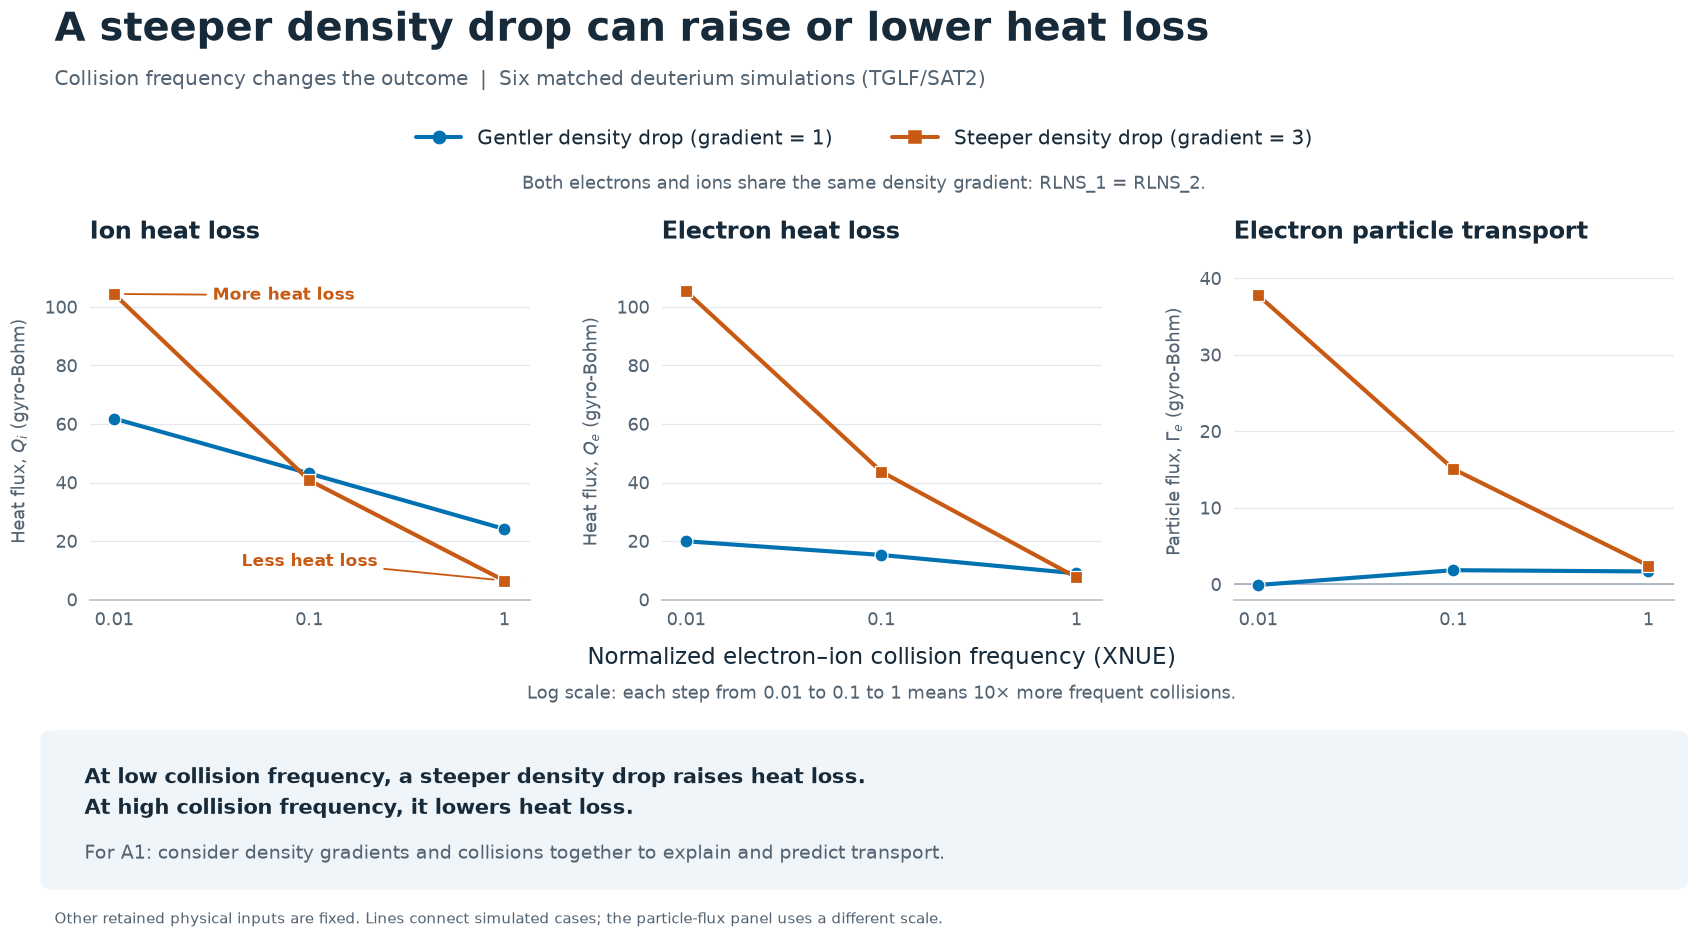

Effect of raising the shared density gradient from 1 to 3:


,change_in_Q_i,change_in_Q_e,change_in_Gamma_e
XNUE,,,
0.01,42.5710,85.3830,37.8834
0.10,-2.3330,28.4810,13.2356
1.00,-17.6481,-1.3263,0.7658


In [4]:
nl_interactions, nl_interaction_coverage = matched_rectangles(nl_df, nl_features, nl_targets)
supported_pairs = nl_interaction_coverage.loc[nl_interaction_coverage["matched_rectangles"].gt(0)]
print(f"Matched comparisons exist for {len(supported_pairs)} of {len(nl_interaction_coverage)} input pairs.")
print(f"{int(supported_pairs['matched_rectangles'].sum())} overlapping rectangles, evaluated for three fluxes.")
display(supported_pairs)
display(nl_interactions.loc[nl_interactions["target"].eq("Q_i")]
        .sort_values("difference_of_differences", key=abs, ascending=False).head(10).round(4))

# The deuterium density/collision grid has all six observed combinations.
held = [name for name in nl_features if name not in {"XNUE", "RLNS_2"}]
keep = np.isclose(nl_df[held].to_numpy(), nl_df.loc["a_D", held].to_numpy(dtype=float),
                  rtol=1e-10, atol=1e-12).all(axis=1)
nl_density_collision = nl_df.loc[keep & nl_df["RLNS_2"].isin([1, 3])].copy()
assert len(nl_density_collision) == 6
# Use plain-language labels while retaining the exact matched data.
from presentation_plots import plot_density_collision_comparison, DENSITY_COLLISION_CAPTION

fig = plot_density_collision_comparison(nl_density_collision)
figure_stem = NL_FIGURE_DIR / "04_density_collision_interaction"
with plt.rc_context({"svg.fonttype": "none"}):
    for extension in ("png", "svg"):
        fig.savefig(figure_stem.with_suffix(f".{extension}"), dpi=240, facecolor="white")
figure_stem.with_name(figure_stem.name + "_caption.txt").write_text(
    DENSITY_COLLISION_CAPTION + "\n"
)
if figure_stem.with_suffix(".png") not in nl_saved_figures:
    nl_saved_figures.append(figure_stem.with_suffix(".png"))
plt.show()
plt.close(fig)

nl_density_effects = []
for collision, group in nl_density_collision.groupby("XNUE"):
    by_density = group.set_index("RLNS_2")
    row = {"XNUE": collision}
    for target in nl_targets:
        row[f"change_in_{target}"] = by_density.at[3.0, target] - by_density.at[1.0, target]
    nl_density_effects.append(row)
nl_density_effects = pd.DataFrame(nl_density_effects).set_index("XNUE")
print("Effect of raising the shared density gradient from 1 to 3:")
display(nl_density_effects.round(4))

**Presentation takeaway.** In these simulations, a steeper density drop increases heat loss when collisions are infrequent, but reduces it when collisions are frequent. For A1, this shows why we need to consider plasma conditions together when explaining or predicting heat loss.

The density-gradient effect on deuterium ion heat flux changes sign:
**+42.571** at `XNUE = 0.01`, **−2.333** at `0.1`, and **−17.6481** at `1`.
The low-to-high collision interaction contrast is **−60.2191** gyro-Bohm units.
Its multiplicative factor is **0.159**, so changing to a log-flux scale does
not remove this particular interaction.

The four supported input pairs are **collisions × density gradient**,
**collisions × mass**, **temperature gradient × mass**, and **density gradient
× mass**. The other **41 pairs lack matched four-corner comparisons**. The
absence of such a comparison is a coverage gap, not evidence of no interaction.

### Does a single mass power law fit the isotope comparisons?

For each complete H/D/T triplet, calculate local exponents between adjacent
masses, using (eta=log(Q_2/Q_1)/log(m_2/m_1)). If a single power law
(Q\propto m^\beta) described a triplet exactly, the H-to-D and D-to-T exponents
would agree. This is a shape check on the three normalized outputs, not a
universal isotope-scaling estimate or an experimental confinement result.

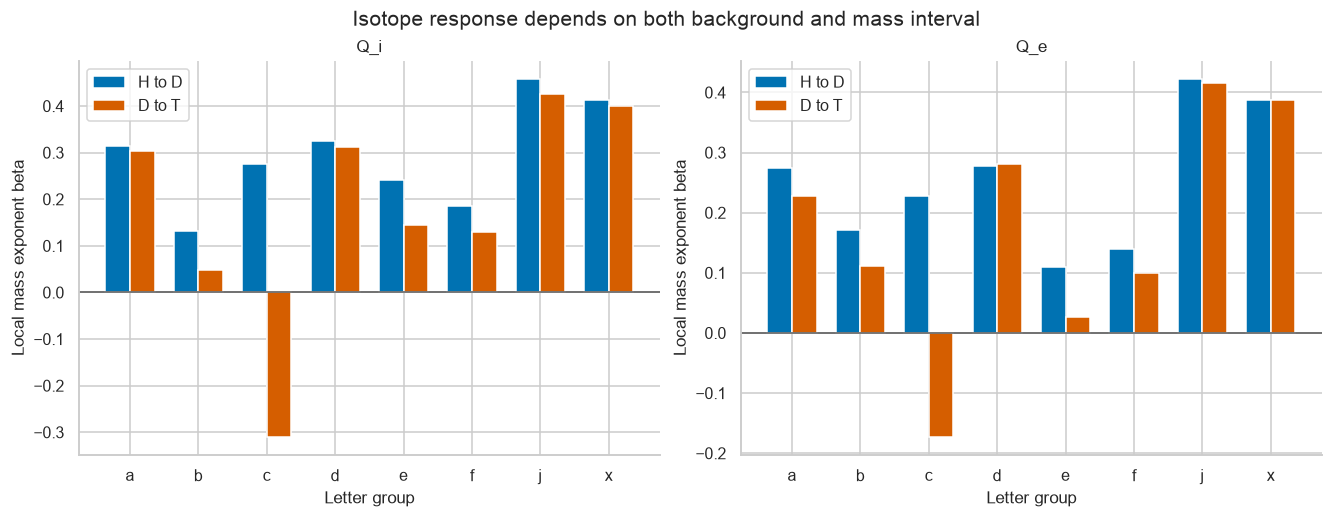

,letter,target,beta_H_to_D,beta_D_to_T
0,a,Q_i,0.314,0.303
1,a,Q_e,0.274,0.228
2,b,Q_i,0.132,0.049
3,b,Q_e,0.171,0.112
4,c,Q_i,0.275,-0.310
5,c,Q_e,0.228,-0.173
6,d,Q_i,0.326,0.313
7,d,Q_e,0.277,0.281
8,e,Q_i,0.241,0.146
9,e,Q_e,0.109,0.026


In [9]:
nl_mass_rows = []
for letter in complete_letters:
    group = nl_df.loc[nl_df["letter"].eq(letter)].set_index("ion")
    for target in ["Q_i", "Q_e"]:
        nl_mass_rows.append({
            "letter": letter, "target": target,
            "beta_H_to_D": np.log(group.at["D", target] / group.at["H", target]) / np.log(2),
            "beta_D_to_T": np.log(group.at["T", target] / group.at["D", target]) / np.log(1.5),
        })
nl_mass_exponents = pd.DataFrame(nl_mass_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
for ax, target in zip(axes, ["Q_i", "Q_e"]):
    table = nl_mass_exponents.loc[nl_mass_exponents["target"].eq(target)].set_index("letter")
    x = np.arange(len(table))
    ax.bar(x - 0.18, table["beta_H_to_D"], width=0.36, color="#0072B2", label="H to D")
    ax.bar(x + 0.18, table["beta_D_to_T"], width=0.36, color="#D55E00", label="D to T")
    ax.axhline(0, color="#555555", linewidth=1)
    ax.set_xticks(x, table.index)
    ax.set(title=target, xlabel="Letter group", ylabel="Local mass exponent beta")
    ax.legend()
fig.suptitle("Isotope response depends on both background and mass interval", fontsize=14)
nl_save(fig, "05_local_isotope_exponents")
display(nl_mass_exponents.round(3))

### Compare simple one-input response shapes

For each physical input and each primary flux, compare a straight line,
quadratic, low-degree spline, and, where the input is positive, log-input and
inverse-input models. Each uses a fixed ridge penalty of 1 after scaling;
these are deliberately limited candidates, not an exhaustive search over all
possible functions. No log transform is applied to signed particle flux.

Each test fold contains an entire letter group. If a training fold has too few
input levels for a quadratic or spline, it falls back to a line, as recorded
in `fallback_folds`. Scalers and spline knots use training cases only. The
`extrapolation_cases` column counts held-out settings outside the training range.

We report **letter-balanced mean absolute error (MAE)**: calculate each
letter's mean absolute error, then average those 26 values. Thus an H/D/T group
has the same total evaluation weight as a D-only letter. Training itself uses
one weight per case. The nonlinear winner in this screen is chosen using these
same scores, so the gain is an exploratory ranking, not an unbiased estimate
for an already selected winner. The multivariate comparison below separately
nests its penalty selection.

Univariate screen finished: Q_i


Univariate screen finished: Q_e


Univariate screen finished: Gamma_e


Evaluated 144 one-input configurations.


,target,input,model,linear_MAE,letter_MAE,letter_R2,MAE_improvement_percent,fallback_folds,extrapolation_cases
2,Gamma_e,XNUE,spline,6.598,5.203,-0.636,21.138,1,0
1,Gamma_e,MASS_2,quadratic,6.143,4.923,-0.032,19.861,0,0
11,Q_e,XNUE,spline,15.717,12.704,-0.347,19.165,1,0
12,Q_e,MASS_2,quadratic,14.895,12.881,-0.048,13.522,0,0
18,Q_i,magnetic_shear,log_x,15.941,15.290,-0.030,4.078,0,2
4,Gamma_e,KAPPA_LOC,quadratic,6.292,6.055,-0.172,3.776,0,1
3,Gamma_e,DRMAJDX_LOC,quadratic,6.215,5.981,-0.159,3.759,0,1
13,Q_e,magnetic_shear,log_x,15.106,14.540,-0.144,3.746,0,2
15,Q_e,KAPPA_LOC,quadratic,15.501,14.925,-0.173,3.717,0,1
5,Gamma_e,magnetic_shear,log_x,6.248,6.062,-0.166,2.976,0,2


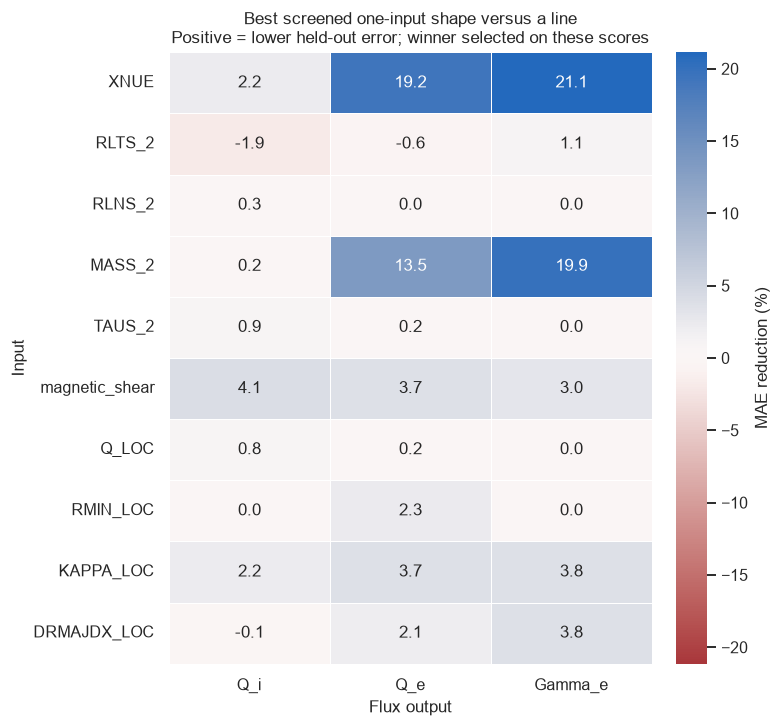

In [10]:
nl_univariate, nl_univariate_predictions = univariate_sweep(
    nl_df, nl_features, nl_targets, nl_groups
)
nl_linear_1d = nl_univariate.loc[nl_univariate["model"].eq("linear"),
                               ["target", "input", "letter_MAE"]].rename(columns={"letter_MAE": "linear_MAE"})
nl_best_1d = (nl_univariate.loc[nl_univariate["model"].ne("linear")]
              .sort_values("letter_MAE").groupby(["target", "input"], sort=False).head(1)
              .merge(nl_linear_1d, on=["target", "input"]))
nl_best_1d["MAE_improvement_percent"] = 100 * (1 - nl_best_1d["letter_MAE"] / nl_best_1d["linear_MAE"])
print(f"Evaluated {len(nl_univariate)} one-input configurations.")
display(nl_best_1d.sort_values("MAE_improvement_percent", ascending=False)[[
    "target", "input", "model", "linear_MAE", "letter_MAE", "letter_R2",
    "MAE_improvement_percent", "fallback_folds", "extrapolation_cases",
]].round(3))

matrix = nl_best_1d.pivot(index="input", columns="target", values="MAE_improvement_percent")
matrix = matrix.reindex(index=nl_features, columns=nl_targets)
limit = max(1, abs(matrix.to_numpy()).max())
fig, ax = plt.subplots(figsize=(7, 6.5), layout="constrained")
sns.heatmap(matrix, annot=True, fmt=".1f", cmap="vlag_r", vmin=-limit, vmax=limit,
            linewidths=0.5, ax=ax, cbar_kws={"label": "MAE reduction (%)"})
ax.set(title="Best screened one-input shape versus a line\nPositive = lower held-out error; winner selected on these scores",
       xlabel="Flux output", ylabel="Input")
ax.grid(False)
nl_save(fig, "06_univariate_model_screen")

The largest one-input MAE gains do not necessarily produce useful predictions.
For example, the collision-frequency spline improves electron-heat-flux MAE by
about **19%** over its one-input line, but its letter-weighted (R^2) is still
**−0.35**. The other inputs vary too, so fitting a pooled one-variable curve
cannot account for all the flux variation. A negative (R^2) here means the
squared errors exceed those relative to the global letter-weighted target
mean; compare the held-out mean model below for a train-only baseline.

### Multivariate models: predict an unseen letter group

We now use all 10 physical inputs together. For every outer fold, all cases of
one letter are held out. An inner five-fold split, also grouped by letter,
selects the ridge penalty from **0.1, 1, 10, 100**. All scaling, polynomial
features, spline knots, and target transformations are fitted within training
folds. This follows the logic of
[group-aware cross-validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.LeaveOneGroupOut.html)
and [nested tuning](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
The family comparison itself remains exploratory; there is no untouched final
test set after searching these alternatives.

| Model | Relationship it can represent |
|---|---|
| `mean` | Training-case mean, a reference prediction |
| `linear` | Additive straight-line effects of raw physical inputs |
| `log_collision_linear` | Additive effects with `log10(XNUE)` replacing collisions |
| `additive_splines` | Separate smooth curves for each input, without interactions |
| `quadratic_interactions` | Curvature and pairwise products, with shrinkage |
| `random_forest` | Nonlinear splits and interactions; fixed 100 trees, depth 4, minimum leaf size 3 |
| `log_heat_linear` | A linear model of log heat flux with log collisions; positive predictions after exponentiation |

The transformed-input regression models use log collisions; the raw linear
model and forest use untransformed collisions. The log-heat model is used only
for the two positive heat outputs. Models do not
use other flux outputs as predictors. Mean, forest, and all other unspecified
settings are fixed, not tuned. Inner tuning minimizes case-level MAE; outer
reporting weights letters equally. Negative heat predictions are counted and
retained in the error scores, rather than clipped away.

Nested group validation finished: Q_i / mean


Nested group validation finished: Q_i / linear


Nested group validation finished: Q_i / log_collision_linear

Nested group validation finished: Q_i / additive_splines


Nested group validation finished: Q_i / quadratic_interactions


Nested group validation finished: Q_i / random_forest


... (11 outputs left out)

Nested group validation finished: Gamma_e / additive_splines


Nested group validation finished: Gamma_e / quadratic_interactions


Nested group validation finished: Gamma_e / random_forest


,target,model,letter_MAE,letter_RMSE,letter_R2,case_MAE,nonpositive_heat_predictions
16,Gamma_e,log_collision_linear,2.725,6.050,0.430,3.901,0
18,Gamma_e,quadratic_interactions,3.210,5.322,0.559,3.537,0
19,Gamma_e,random_forest,3.484,7.493,0.126,4.821,0
15,Gamma_e,linear,3.520,6.674,0.306,4.235,0
17,Gamma_e,additive_splines,3.911,7.951,0.016,5.474,0
14,Gamma_e,mean,6.127,8.676,-0.172,7.322,0
13,Q_e,log_heat_linear,5.306,9.175,0.799,6.369,0
11,Q_e,quadratic_interactions,7.253,12.160,0.648,8.178,3
9,Q_e,log_collision_linear,7.695,15.424,0.433,10.427,2
8,Q_e,linear,10.215,17.735,0.250,11.381,2


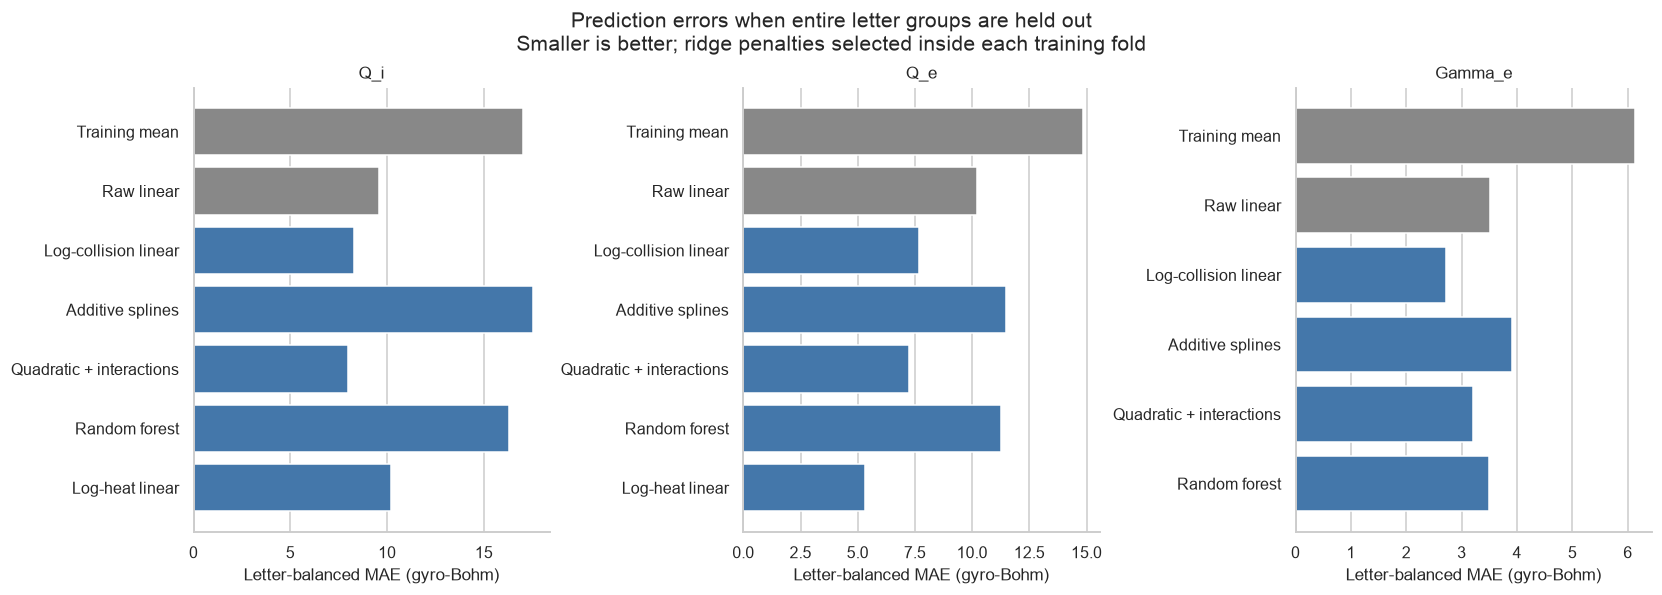

In [11]:
nl_models, nl_model_predictions, nl_tuning = nested_model_comparison(
    nl_df, nl_features, nl_targets, nl_groups
)
display(nl_models.sort_values(["target", "letter_MAE"]).round(3))

model_order = ["mean", "linear", "log_collision_linear", "additive_splines",
               "quadratic_interactions", "random_forest", "log_heat_linear"]
model_labels = {
    "mean": "Training mean", "linear": "Raw linear", "log_collision_linear": "Log-collision linear",
    "additive_splines": "Additive splines", "quadratic_interactions": "Quadratic + interactions",
    "random_forest": "Random forest", "log_heat_linear": "Log-heat linear",
}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.3), layout="constrained")
for ax, target in zip(axes, nl_targets):
    table = nl_models.loc[nl_models["target"].eq(target)].set_index("model")
    order = [name for name in model_order if name in table.index]
    values = table.loc[order, "letter_MAE"]
    ax.barh(np.arange(len(order)), values, color=["#888888" if name in {"mean", "linear"} else "#4477AA" for name in order])
    ax.set_yticks(np.arange(len(order)), [model_labels[name] for name in order])
    ax.invert_yaxis()
    ax.set(title=target, xlabel="Letter-balanced MAE (gyro-Bohm)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Prediction errors when entire letter groups are held out\nSmaller is better; ridge penalties selected inside each training fold", fontsize=14)
nl_save(fig, "07_grouped_model_comparison")

,target,selected_model,letters_improved_vs_raw_linear,MAE_gain_vs_raw_linear_percent,MAE_gain_vs_log_collision_linear_percent,largest_benefit_letter,gain_without_that_scored_letter_percent
0,Q_i,quadratic_interactions,16,16.771,3.983,x,6.027
1,Q_e,log_heat_linear,19,48.055,31.041,k,40.130
2,Gamma_e,log_collision_linear,24,22.569,0.000,k,18.068


The last column deletes one letter from scoring only; it does not refit the models.


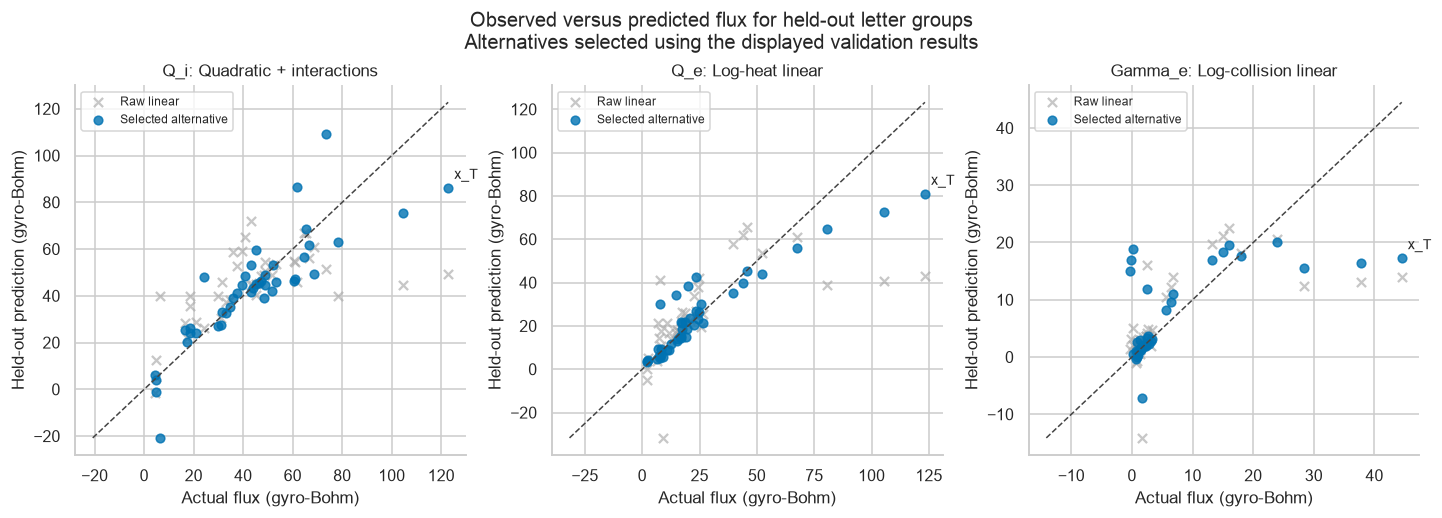

Nonpositive heat predictions from the selected heat models:


,case,target,model,actual,prediction
177,b_T,Q_i,quadratic_interactions,4.8956,-1.3369
214,z_D,Q_i,quadratic_interactions,6.4899,-20.7826


In [12]:
nl_model_predictions["absolute_error"] = (
    nl_model_predictions["actual"] - nl_model_predictions["prediction"]
).abs()
nl_letter_errors = (nl_model_predictions.groupby(["target", "model", "letter"])["absolute_error"]
                    .mean().unstack("model"))
nl_selected = (nl_models.loc[~nl_models["model"].isin(["mean", "linear"])]
               .sort_values("letter_MAE").groupby("target", sort=False).head(1).set_index("target"))
nl_stability_rows = []
for target in nl_targets:
    chosen = nl_selected.at[target, "model"]
    errors_by_letter = nl_letter_errors.loc[target]
    gains = errors_by_letter["linear"] - errors_by_letter[chosen]
    influential = gains.idxmax()
    remaining = errors_by_letter.drop(influential)
    nl_stability_rows.append({
        "target": target, "selected_model": chosen,
        "letters_improved_vs_raw_linear": int(gains.gt(0).sum()),
        "MAE_gain_vs_raw_linear_percent": 100 * (1 - errors_by_letter[chosen].mean() / errors_by_letter["linear"].mean()),
        "MAE_gain_vs_log_collision_linear_percent": 100 * (1 - errors_by_letter[chosen].mean() / errors_by_letter["log_collision_linear"].mean()),
        "largest_benefit_letter": influential,
        "gain_without_that_scored_letter_percent": 100 * (1 - remaining[chosen].mean() / remaining["linear"].mean()),
    })
nl_stability = pd.DataFrame(nl_stability_rows)
display(nl_stability.round(3))
print("The last column deletes one letter from scoring only; it does not refit the models.")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), layout="constrained")
for ax, target in zip(axes, nl_targets):
    chosen = nl_selected.at[target, "model"]
    best = nl_model_predictions.loc[nl_model_predictions["target"].eq(target) & nl_model_predictions["model"].eq(chosen)]
    linear = nl_model_predictions.loc[nl_model_predictions["target"].eq(target) & nl_model_predictions["model"].eq("linear")]
    ax.scatter(linear["actual"], linear["prediction"], color="#AAAAAA", marker="x", alpha=0.65, label="Raw linear")
    ax.scatter(best["actual"], best["prediction"], color="#0072B2", s=32, alpha=0.8, label="Selected alternative")
    lo = min(best["actual"].min(), best["prediction"].min(), linear["prediction"].min())
    hi = max(best["actual"].max(), best["prediction"].max(), linear["prediction"].max())
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="#444444", linewidth=1)
    worst = best.loc[best["absolute_error"].idxmax()]
    ax.annotate(worst["case"], (worst["actual"], worst["prediction"]), xytext=(4, 6), textcoords="offset points", fontsize=9)
    ax.set(title=f"{target}: {model_labels[chosen]}", xlabel="Actual flux (gyro-Bohm)", ylabel="Held-out prediction (gyro-Bohm)")
    ax.legend(fontsize=8)
fig.suptitle("Observed versus predicted flux for held-out letter groups\nAlternatives selected using the displayed validation results", fontsize=13)
nl_save(fig, "08_held_out_predictions")

print("Nonpositive heat predictions from the selected heat models:")
invalid_selected = pd.concat([
    nl_model_predictions.loc[nl_model_predictions["target"].eq(target)
                             & nl_model_predictions["model"].eq(nl_selected.at[target, "model"])
                             & nl_model_predictions["prediction"].le(0)]
    for target in ["Q_i", "Q_e"]
])
display(invalid_selected[["case", "target", "model", "actual", "prediction"]].round(4))

### What survived the broader search?

**The density/collision interaction has direct matched-case evidence.** For
D, a density-gradient increase raises `Q_i` at low collisions and lowers it at
high collisions. This reversal is more informative than a pooled correlation.
The mass interactions also have matched comparisons, but most other input pairs
lack the combinations needed to isolate an interaction.

**Some useful nonlinear behavior is captured by simple transformations.**
For electron heat flux, the log-heat model reduces letter-balanced MAE from
**10.215 to 5.306**, about **48%**, compared with raw linear regression. It
improves the error for **19 of 26 letters** and keeps heat predictions positive.
For electron particle flux, replacing collisions with their log reduces MAE
from **3.520 to 2.725**, about **23%**, and improves **24 of 26 letters**.

**The ion-heat model result is less decisive.** The quadratic/interaction model
reduces MAE from **9.570 to 7.965**, about **17%** versus raw linear regression,
but improves only about **4%** over the simpler log-collision linear model.
Dropping its most favorable scored letter (`x`) reduces the advantage over raw
linear regression to about **6%**. It also predicts negative heat flux for
`b_T` and `z_D`. It is an exploratory candidate, not a physically reliable
surrogate. Neither clipping predictions nor choosing a different scoring
metric after seeing them would independently validate the model.

**More flexibility does not automatically help.** Additive splines and the
fixed random forest perform worse than the simpler alternatives here. The
controlled density scan and isotope triplet `c` show nonmonotonic behavior,
but there are too few settings to establish detailed curves, thresholds, or a
single isotope scaling law. Momentum patterns need a separate check of output
magnitudes and numerical behavior before drawing physical conclusions.

Useful follow-up simulations would fill the density/collision grid at
intermediate collisions for every isotope, add temperature-gradient points
near the observed changes in slope, and vary electron and ion gradients
separately. New cases would provide a stronger check than searching more
functions on these same 43 rows.

The original assignment's Step 4 and final quality-flagged CSV remain to be
done. The nonlinear exploration is saved below so its full tables can be
inspected without relying on only the displayed top rows.

In [13]:
nl_results_path = analysis_dir / "nonlinear_results.json"
nl_tables = {
    "input_coverage": nl_coverage.reset_index(names="input"),
    "dependencies": nl_dependencies,
    "controlled_scan_slopes": nl_scan_slopes,
    "interaction_coverage": nl_interaction_coverage,
    "matched_interactions": nl_interactions,
    "local_mass_exponents": nl_mass_exponents,
    "univariate_model_scores": nl_univariate,
    "multivariate_model_scores": nl_models,
    "multivariate_held_out_predictions": nl_model_predictions,
    "multivariate_tuning": nl_tuning,
    "model_stability": nl_stability,
}
nl_payload = {
    "case_count": len(nl_df), "letter_count": len(set(nl_groups)),
    "primary_targets": nl_targets, "physical_inputs": nl_features,
    "evaluation": "Outer leave-one-letter-out; inner grouped ridge tuning; exploratory family comparison",
    "tables": {name: json.loads(table.to_json(orient="records", double_precision=15)) for name, table in nl_tables.items()},
    "figure_files": [str(path.relative_to(analysis_dir)) for path in nl_saved_figures],
}
nl_results_path.write_text(json.dumps(nl_payload, indent=2, allow_nan=False) + "\n")
print(f"Saved {len(nl_saved_figures)} nonlinear-exploration figures and all result tables.")
print(nl_results_path)

Saved 11 nonlinear-exploration figures and all result tables.
/Users/ryanlindberg/Desktop/Classes/DSC180A/assignments/A1/analysis/nonlinear_results.json
